In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from pathlib import Path

In [ ]:
GRAPHS = {
    "dblp": Path("tc_res/com-dblp-sym"),
    "lj":   Path("tc_res/com-lj-sym"),
    "youtube":  Path("tc_res/youtube-sym"),
}

In [4]:
def get_stat(df, region, category):
    s = df.loc[(df["REGION"] == region) & (df["CATEGORY"] == category), "TOTAL"]
    s = pd.to_numeric(s, errors="coerce")
    return s.iloc[0] if len(s) else np.nan

In [27]:
def median_stat(df, region_pat, category_pat):
    m = df["REGION"].str.fullmatch(region_pat) & df["CATEGORY"].str.fullmatch(category_pat)
    return pd.to_numeric(df.loc[m, "TOTAL"], errors="coerce").median()

In [5]:
rows = []
for graph, folder in GRAPHS.items():
    for path in sorted(folder.glob("n*_t*.csv")):
        
        m = re.fullmatch(r"n(\d+)_t(\d+)\.csv", path.name)
        if not m:
            continue
        n, t = int(m.group(1)), int(m.group(2))

        df = pd.read_csv(path, skipinitialspace=True)
        df["REGION"] = df["REGION"].astype(str).str.strip()
        df["CATEGORY"] = df["CATEGORY"].astype(str).str.strip()

        timer_mask = (df["REGION"] == "TC") & df["CATEGORY"].str.fullmatch(r"Timer_[0-9]")
        avg_timer = pd.to_numeric(df.loc[timer_mask, "TOTAL"], errors="coerce").median()

        loop_mask = df["REGION"].str.fullmatch(r"TC_[0-9]") & (df["CATEGORY"] == "Time")
        avg_loop = pd.to_numeric(df.loc[loop_mask, "TOTAL"], errors="coerce").median()

        rows.append({
            "graph": graph,
            "hosts": n,
            "threads": t,
            "replication_factor_nodes": get_stat(df, "dGraph_Mining", "ReplicationFactorNodes"),
            "replication_factor_edges": get_stat(df, "dGraph_Mining", "ReplicatonFactorEdges"),
            "edge_inspection_bytes_sent": get_stat(df, "dGraph_Mining", "EdgeInspectionBytesSent"),
            "edge_loading_bytes_sent": get_stat(df, "dGraph_Mining", "EdgeLoadingBytesSent"),
            "median_timer_ms": avg_timer,
            "median_tc_loop_ms": avg_loop,
            "graph_construct_time": get_stat(df, "DistBench", "GraphConstructTime"),
            "edge_inspection_time": get_stat(df, "dGraph_Mining", "EdgeInspection"),
            "edge_loading_time": get_stat(df, "dGraph_Mining", "EdgeLoading")
        })

In [6]:
result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("tc_stats.csv", index=False)

In [7]:
df = pd.read_csv('tc_stats.csv')
df

,graph,hosts,threads,replication_factor_nodes,replication_factor_edges,edge_inspection_bytes_sent,edge_loading_bytes_sent,median_timer_ms,median_tc_loop_ms,graph_construct_time,edge_inspection_time,edge_loading_time
0,dblp,1,1,1.00000,1.00000,0,0,45.0,45.0,93,45,30
1,dblp,1,2,1.00000,1.00000,0,0,23.0,23.0,47,26,15
2,dblp,1,3,1.00000,1.00000,0,0,16.0,16.0,36,21,10
3,dblp,1,4,1.00000,1.00000,0,0,13.0,13.0,35,19,10
4,dblp,1,5,1.00000,1.00000,0,0,11.0,11.0,33,18,10
5,dblp,1,6,1.00000,1.00000,0,0,10.0,10.0,34,18,10
6,dblp,1,7,1.00000,1.00000,0,0,9.5,9.5,30,16,9
7,dblp,1,8,1.00000,1.00000,0,0,18.0,18.0,49,26,17
8,dblp,2,1,1.13293,1.25333,3407680,2998768,35.0,35.0,68,33,30
9,dblp,2,2,1.13293,1.25333,3407680,2998768,20.0,20.0,53,24,24


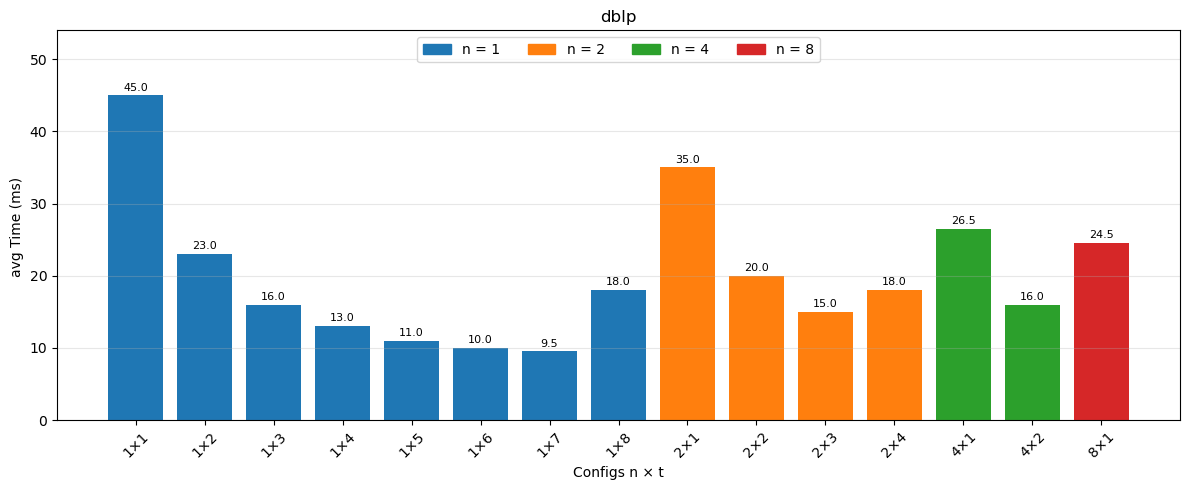

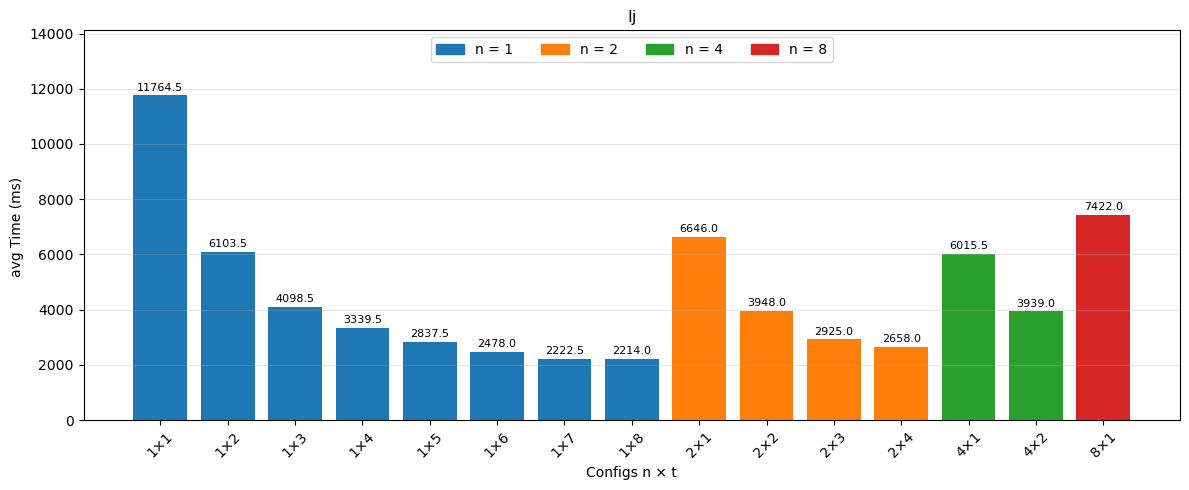

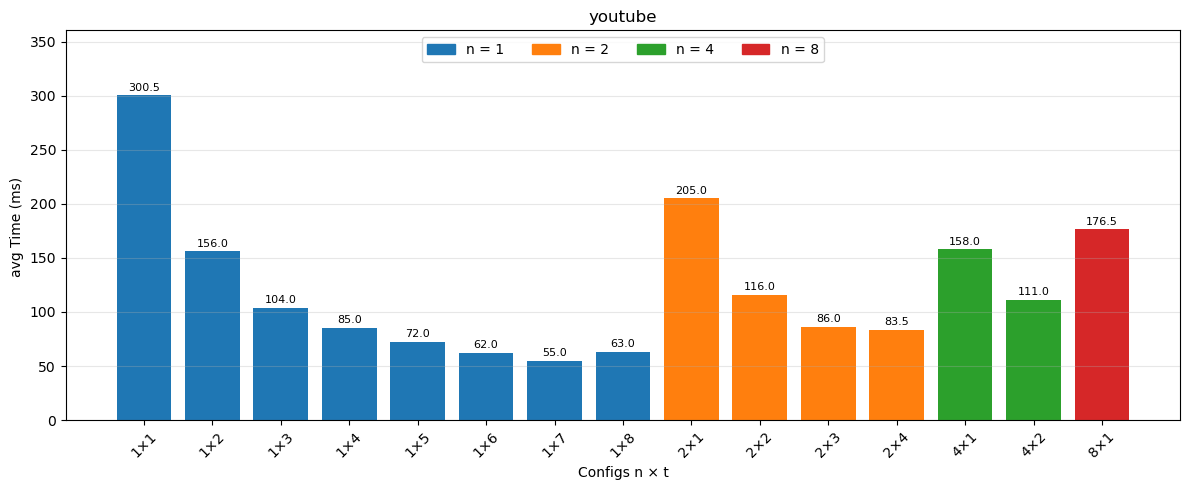

In [8]:
df = df.sort_values(["graph", "hosts", "threads"])

hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, sub["median_tc_loop_ms"], color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("Configs n × t")
    ax.set_ylabel("avg Time (ms) ")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)                                        # место под легенду и подписи сверху

    # Легенда по центру сверху, в одну строку
    present = sorted(sub["hosts"].unique())
    ax.legend(handles=[Patch(color=color_of[n], label=f"n = {n}") for n in present],
              loc="upper center", ncol=len(present))

    fig.tight_layout()
    fig.savefig(f"avg_time_{g}.png", dpi=150)
    plt.show()

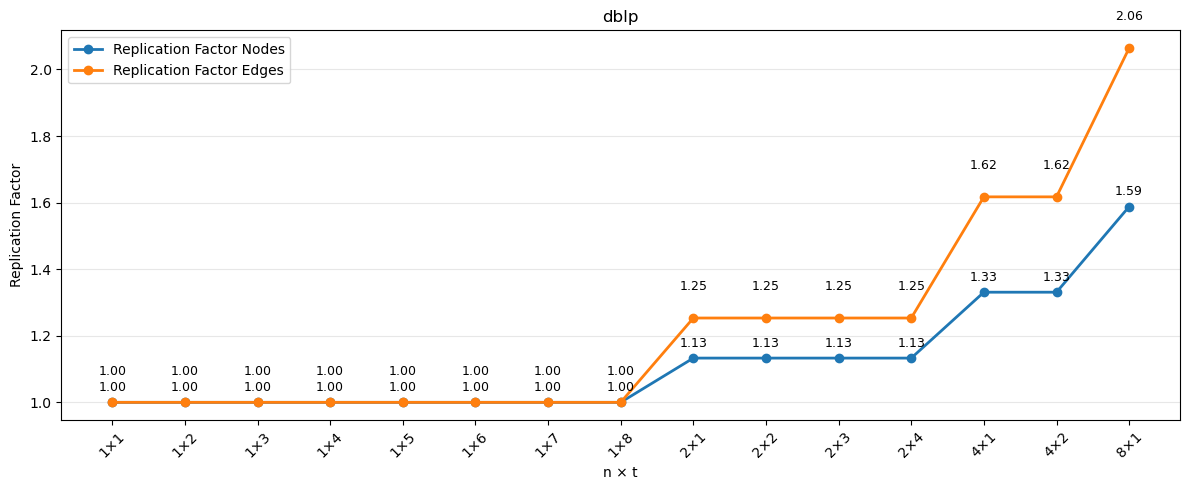

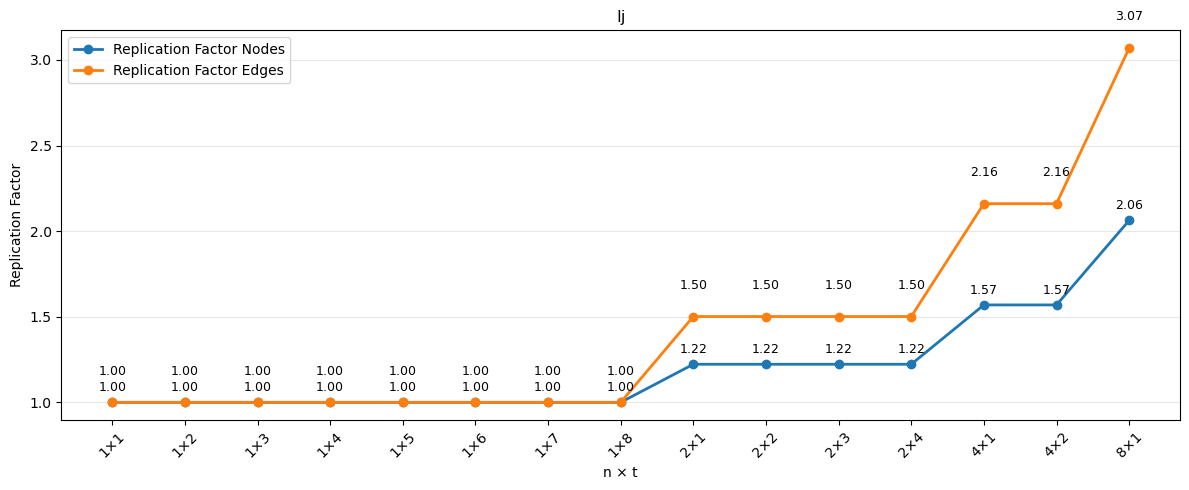

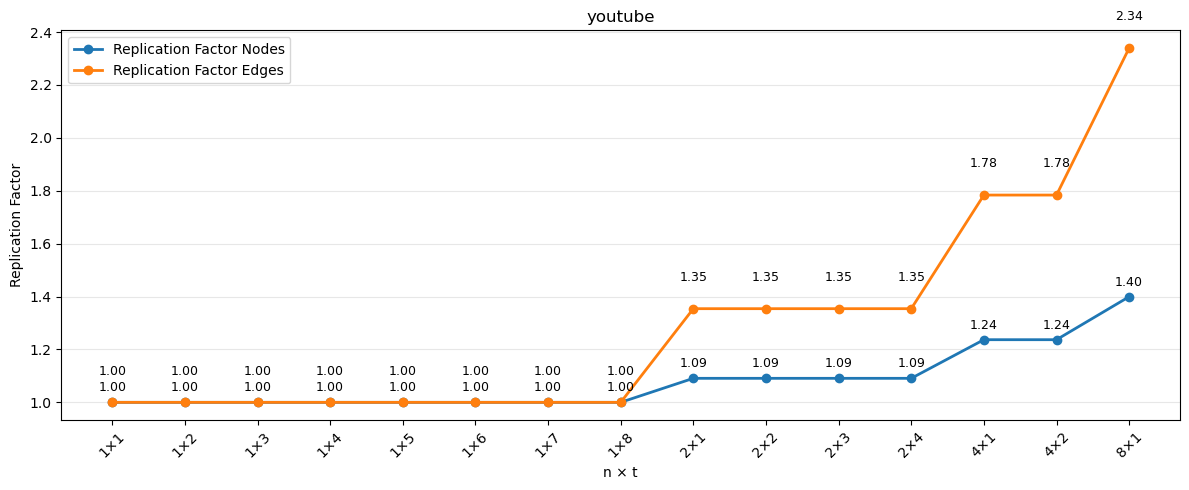

In [22]:
df = df.sort_values(["graph", "hosts", "threads"])

for g in df["graph"].unique():
    sub = df[df["graph"] == g].copy()

    # Конфигурация на оси X
    sub["config"] = (
        sub["hosts"].astype(str) + "×" +
        sub["threads"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    # Line 1 — nodes
    ax.plot(
        sub["config"],
        sub["replication_factor_nodes"],
        marker="o",
        linewidth=2,
        label="Replication Factor Nodes"
    )

    # Подписи значений nodes
    for i, value in enumerate(sub["replication_factor_nodes"]):
        ax.annotate(
            f"{value:.2f}",
            (i, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    # Line 2 — edges
    ax.plot(
        sub["config"],
        sub["replication_factor_edges"],
        marker="o",
        linewidth=2,
        label="Replication Factor Edges"
    )

    # Подписи значений edges
    for i, value in enumerate(sub["replication_factor_edges"]):
        ax.annotate(
            f"{value:.2f}",
            (i, value),
            xytext=(0, 20),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("Replication Factor")

    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(f"replication_factor_{g}.png", dpi=150)
    plt.show()

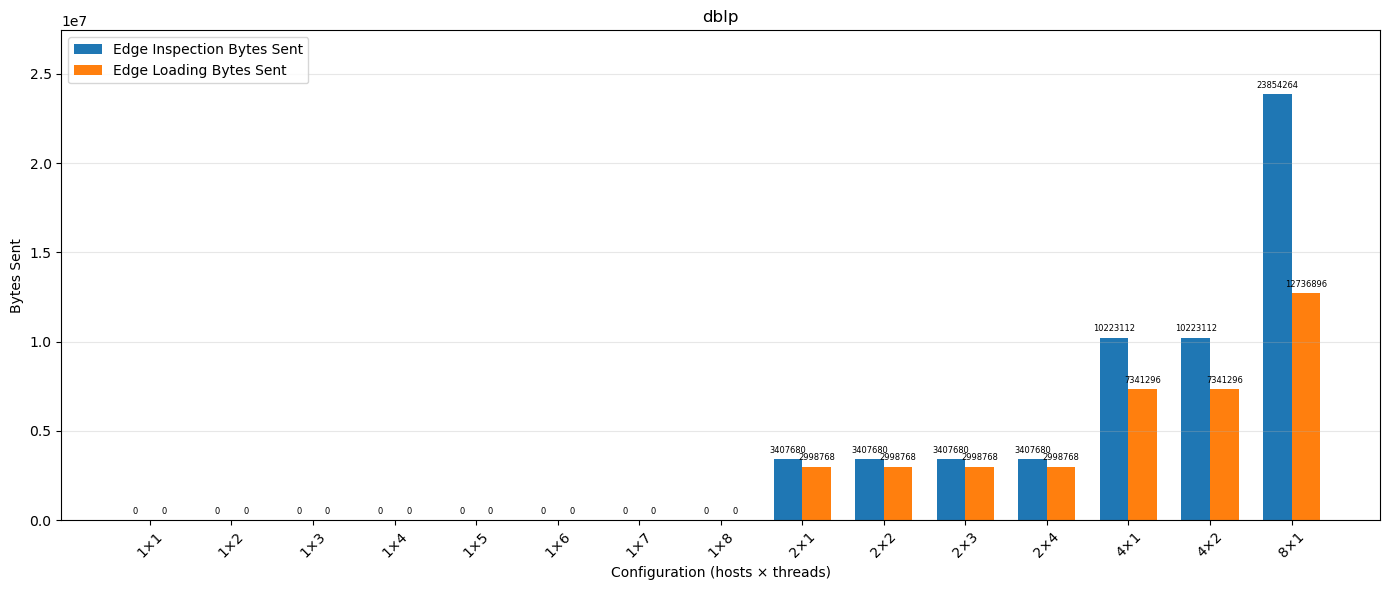

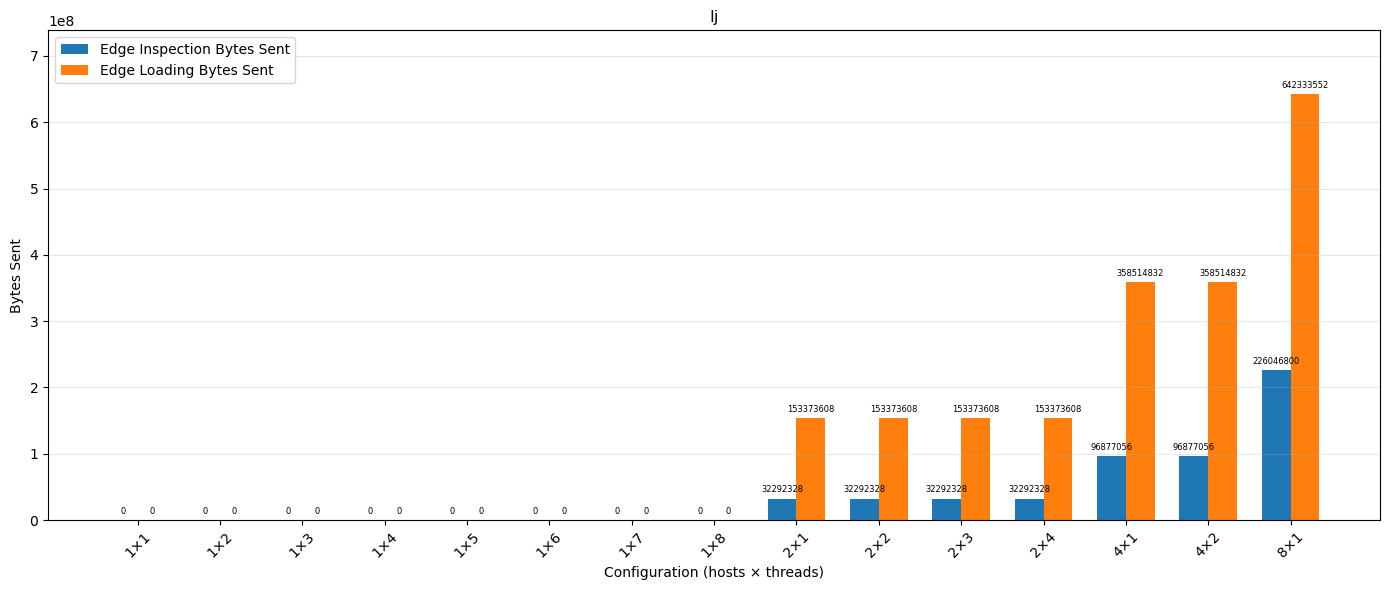

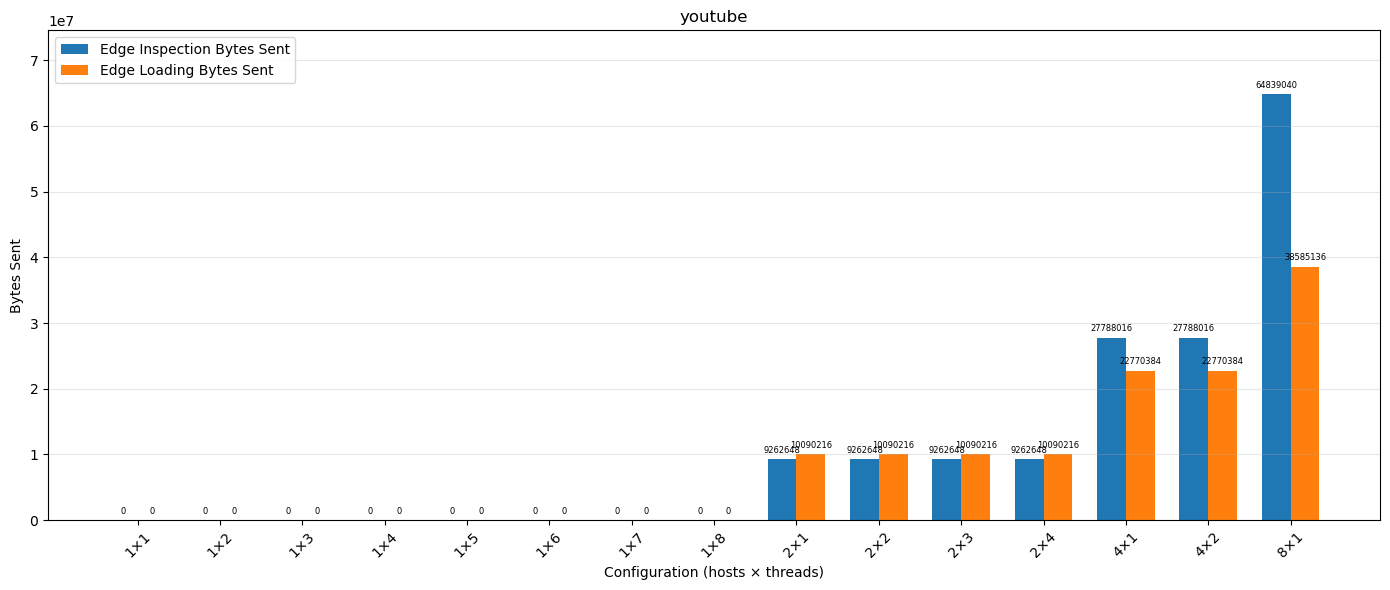

In [13]:
df = df.copy()
df.columns = df.columns.str.strip()

# Конфигурация hosts × threads
df["config"] = (
    df["hosts"].astype(str) + "×" +
    df["threads"].astype(str)
)

for g in df["graph"].unique():
    sub = df[df["graph"] == g].copy()

    # Максимальные значения для каждой конфигурации
    result = (
        sub.groupby(["hosts", "threads", "config"], as_index=False)[
            ["edge_inspection_bytes_sent", "edge_loading_bytes_sent"]
        ]
        .max()
        .sort_values(["hosts", "threads"])
    )

    x = np.arange(len(result))
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 6))

    bars1 = ax.bar(
        x - width / 2,
        result["edge_inspection_bytes_sent"],
        width,
        label="Edge Inspection Bytes Sent"
    )

    bars2 = ax.bar(
        x + width / 2,
        result["edge_loading_bytes_sent"],
        width,
        label="Edge Loading Bytes Sent"
    )

    # Значения над bars
    ax.bar_label(
        bars1,
        fmt="%.0f",
        padding=3,
        fontsize=6
    )

    ax.bar_label(
        bars2,
        fmt="%.0f",
        padding=3,
        fontsize=6
    )

    ax.set_title(g)
    ax.set_xlabel("Configuration (hosts × threads)")
    ax.set_ylabel("Bytes Sent")

    ax.set_xticks(x)
    ax.set_xticklabels(result["config"], rotation=45)

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    # Немного места сверху под значения
    ax.margins(y=0.15)

    fig.tight_layout()
    fig.savefig(f"edge_bytes_{g}.png", dpi=150)
    plt.show()

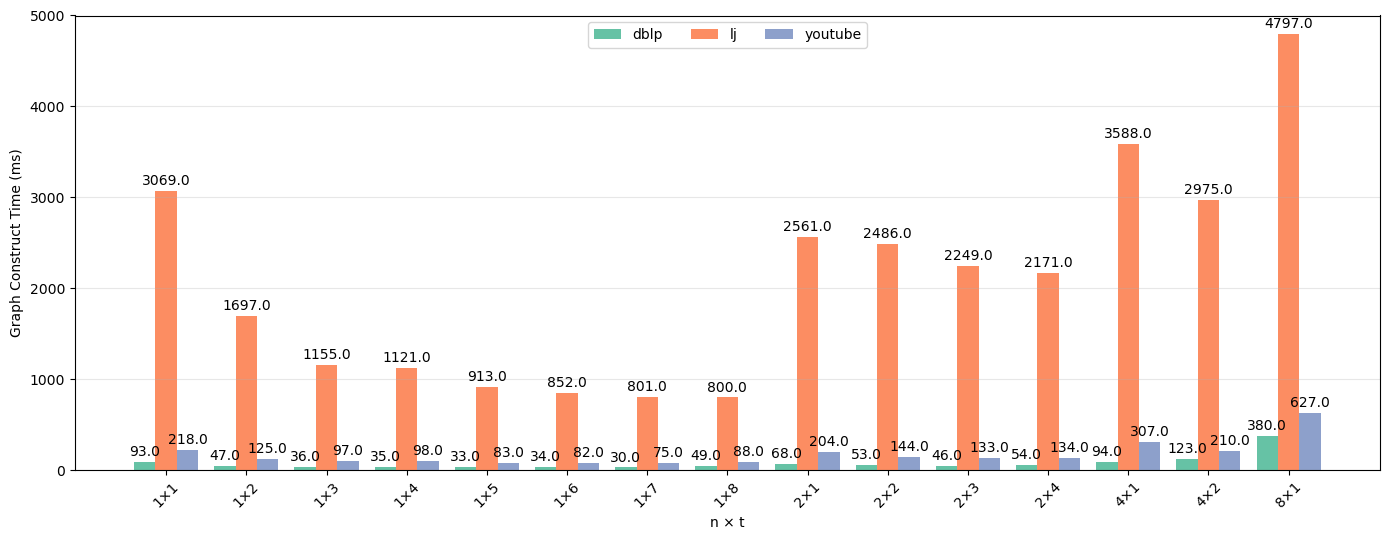

In [34]:
pivot = (df.pivot_table(index=["hosts", "threads"], columns="graph",
                        values="graph_construct_time"))
pivot = pivot.dropna(how="all")          # конфигурации без данных (например, n=1) не рисуем

configs = [f"{n}×{t}" for n, t in pivot.index]
graphs = list(pivot.columns)
x = np.arange(len(configs))
w = 0.8 / len(graphs)                    # ширина одного столбца
cmap = plt.get_cmap("Set2")

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, g in enumerate(graphs):
    vals = pivot[g].values
    bars = ax.bar(x + (i - (len(graphs) - 1) / 2) * w, vals, w, label=g, color=cmap(i))
    ax.bar_label(bars, labels=[f"{v:.1f}" if not np.isnan(v) else "" for v in vals],
                 padding=2, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=45)
ax.set_xlabel("n × t")
ax.set_ylabel("Graph Construct Time (ms)")
ax.set_ylim(0, 5000)  # ось Y от 0 до 5000
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.25)
ax.legend(loc="upper center", ncol=len(graphs))

fig.tight_layout()
fig.savefig("construct.png", dpi=150)
plt.show()

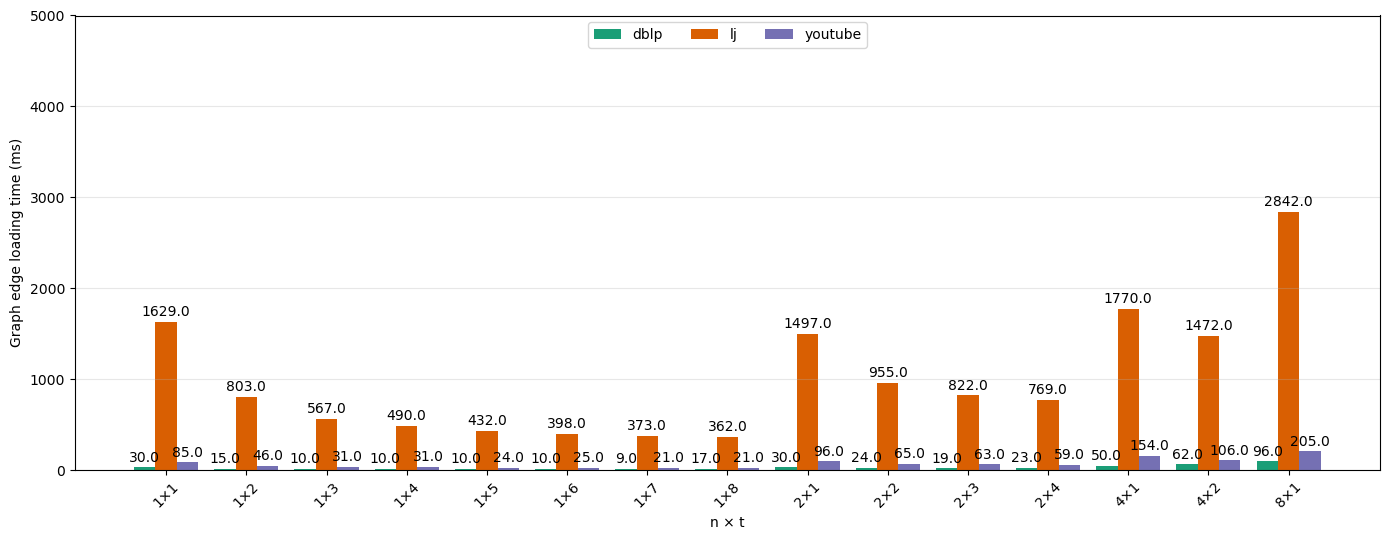

In [27]:
pivot = (df.pivot_table(index=["hosts", "threads"], columns="graph",
                        values="edge_loading_time"))
pivot = pivot.dropna(how="all")          # конфигурации без данных (например, n=1) не рисуем

configs = [f"{n}×{t}" for n, t in pivot.index]
graphs = list(pivot.columns)
x = np.arange(len(configs))
w = 0.8 / len(graphs)                    # ширина одного столбца
cmap = plt.get_cmap("Dark2")

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, g in enumerate(graphs):
    vals = pivot[g].values
    bars = ax.bar(x + (i - (len(graphs) - 1) / 2) * w, vals, w, label=g, color=cmap(i))
    ax.bar_label(bars, labels=[f"{v:.1f}" if not np.isnan(v) else "" for v in vals],
                 padding=2, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=45)
ax.set_xlabel("n × t")
ax.set_ylabel("Graph edge loading time (ms)")
ax.set_ylim(0, 5000)  # ось Y от 0 до 5000
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.25)
ax.legend(loc="upper center", ncol=len(graphs))

fig.tight_layout()
fig.savefig("construct.png", dpi=150)
plt.show()

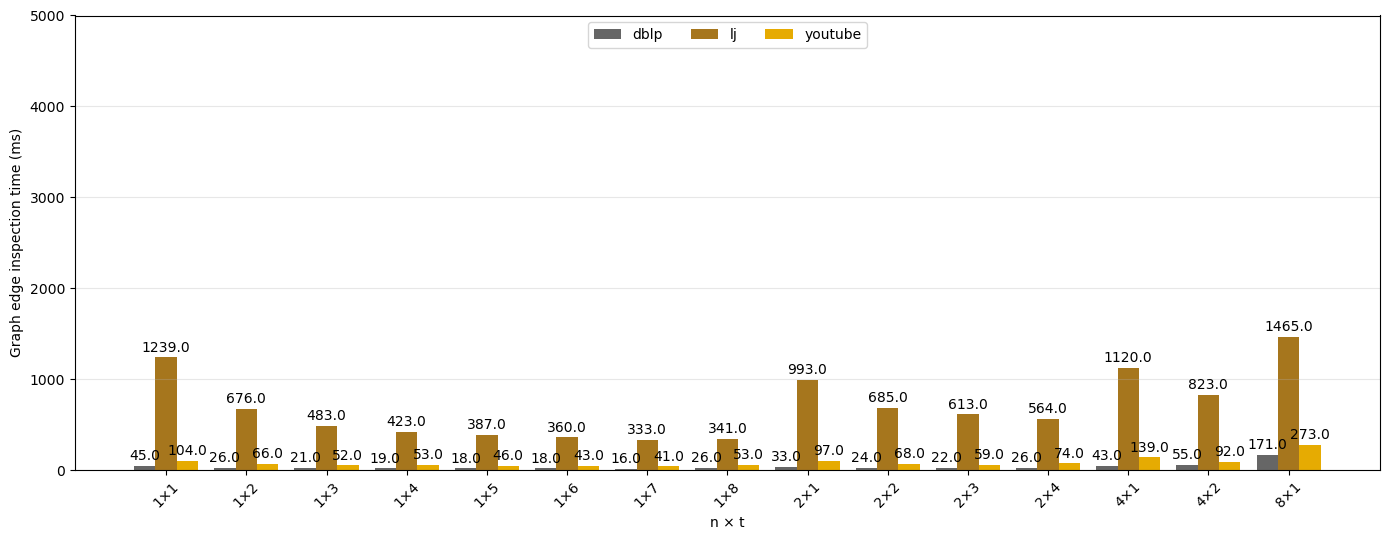

In [30]:
pivot = (df.pivot_table(index=["hosts", "threads"], columns="graph",
                        values="edge_inspection_time"))
pivot = pivot.dropna(how="all")          # конфигурации без данных (например, n=1) не рисуем

configs = [f"{n}×{t}" for n, t in pivot.index]
graphs = list(pivot.columns)
x = np.arange(len(configs))
w = 0.8 / len(graphs)                    # ширина одного столбца
cmap = plt.get_cmap("Dark2_r")

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, g in enumerate(graphs):
    vals = pivot[g].values
    bars = ax.bar(x + (i - (len(graphs) - 1) / 2) * w, vals, w, label=g, color=cmap(i))
    ax.bar_label(bars, labels=[f"{v:.1f}" if not np.isnan(v) else "" for v in vals],
                 padding=2, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=45)
ax.set_xlabel("n × t")
ax.set_ylabel("Graph edge inspection time (ms)")
ax.set_ylim(0, 5000)  # ось Y от 0 до 5000
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.25)
ax.legend(loc="upper center", ncol=len(graphs))

fig.tight_layout()
fig.savefig("construct.png", dpi=150)
plt.show()